# Práctica 2.3 — K-means: tipos de municipios sin etiquetas

Este cuaderno acompaña la clase «K-means» del tema 2.3 (aprendizaje no supervisado). No hay una variable Y que predecir: se buscan **grupos de municipios parecidos** a partir de sus privaciones. Sigue el recorrido de la clase:

1. Datos · 2. **¿Por qué escalar?** · 3. El algoritmo, a mano · 4. Otro inicio, otro resultado · 5. **¿Cuántos grupos?** Codo y silueta · 6. La silueta de cada municipio · 7. **Perfil de los grupos**, mapa y regiones · 8. Estabilidad · 9. Línea base: terciles del IPM · 10. Con las 15 privaciones

**Datos.** `datos/ej2_privaciones_ipm_2018.csv`: 1.122 municipios **reales**, con las 15 privaciones del IPM (índice de pobreza multidimensional) del DANE, censo 2018, en porcentaje de personas. La clase usa dos: **bajo logro educativo** y **sin acceso a agua mejorada**. Es la misma base del ejercicio 02 (PCA y K-means), que sigue a este cuaderno.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

def encuadre(ax):
    """Encuadra el mapa en Colombia continental (San Andrés queda fuera del recuadro)."""
    ax.set_xlim(-79.3, -66.7); ax.set_ylim(-4.4, 12.6); ax.set_axis_off()

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

# Colores de los grupos, como en la clase: de azul (menos privación) a naranja (más), pasando por morado
MORADO = '#8a4fd1'
COL_G = [AZUL, MORADO, NARANJA]

## 1. Datos

In [3]:
df = pd.read_csv(DATOS / 'ej2_privaciones_ipm_2018.csv')
PRIV = list(df.columns[5:20])                     # las 15 privaciones del IPM
V = ['bajo_logro_educativo', 'sin_agua_mejorada']  # las dos variables de la clase
print(f'{len(df)} municipios, {len(PRIV)} privaciones; faltantes: {df[PRIV].isna().sum().sum()}')
df[V + ['ipm']].describe().T

1122 municipios, 15 privaciones; faltantes: 0


,count,mean,std,min,25%,50%,75%,max
bajo_logro_educativo,"1,122.000",66.962,12.675,18.300,61.000,69.900,76.000,96.200
sin_agua_mejorada,"1,122.000",27.114,21.929,0.200,9.800,21.400,38.700,99.000
ipm,"1,122.000",41.792,17.346,4.500,30.225,40.800,52.675,98.500


Son 1.122 municipios con las 15 privaciones y ningún dato faltante. En promedio, el 67,0 % de las personas de un municipio vive en un hogar con **bajo logro educativo** (desviación 12,7) y el 27,1 % **sin acceso a agua mejorada** (desviación 21,9, con municipios desde 0,2 % hasta 99,0 %). El IPM promedio es 41,8 %.

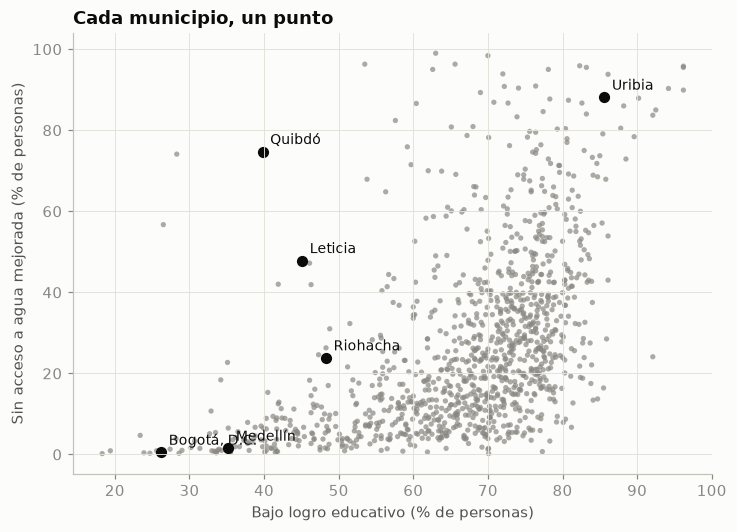

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(df[V[0]], df[V[1]], s=12, color=GRIS, alpha=.7, edgecolor='none')
for m in ['Bogotá, D.C.', 'Medellín', 'Riohacha', 'Leticia', 'Quibdó', 'Uribia']:
    f = df[df.municipio == m].iloc[0]
    ax.scatter(f[V[0]], f[V[1]], s=40, color=TINTA); ax.annotate(m, (f[V[0]], f[V[1]]), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Bajo logro educativo (% de personas)', ylabel='Sin acceso a agua mejorada (% de personas)',
       title='Cada municipio, un punto')
plt.show()

A simple vista no hay grupos nítidos: es una nube continua que sube hacia la derecha. Bogotá y Medellín quedan abajo a la izquierda (poco rezago y casi todos con agua) y Uribia arriba a la derecha. **K-means siempre devuelve k grupos, aunque los datos no los tengan bien separados**: por eso las secciones 5 a 9 se dedican a revisar si los grupos valen la pena.

## 2. ¿Por qué escalar?

K-means mide la distancia en línea recta. Si una variable varía más en sus unidades, pesa más en la distancia. Se agrupa la misma base de tres formas (k = 3) y se compara cada una con la versión escalada mediante el **índice de Rand ajustado** (ARI, *Adjusted Rand Index*: 1 = la misma agrupación, 0 = lo que daría el azar).

In [5]:
Z = StandardScaler().fit_transform(df[V])          # z = (valor − media) / desviación
print('Desviación estándar en %:', df[V].std(ddof=0).round(1).to_dict())

def kmeans(X, k, n_init=10, semilla=SEMILLA):
    return KMeans(n_clusters=k, n_init=n_init, random_state=semilla).fit(X)

def ordenar(etq, valor):
    """Renombra los grupos de 0 a k−1 según el promedio de «valor» (de menos a más privación)."""
    orden = pd.Series(valor).groupby(etq).mean().sort_values().index
    return pd.Series(etq).map({g: i for i, g in enumerate(orden)}).to_numpy()

privacion = df[V].sum(axis=1).to_numpy()
versiones = {'Agua en proporción (0 a 1)': df[V].to_numpy() * [1, 0.01],
             'Las dos en %, sin escalar': df[V].to_numpy(),
             'Las dos escaladas (z)': Z}
etq = {n: ordenar(kmeans(X, 3).labels_, privacion) for n, X in versiones.items()}
ref = etq['Las dos escaladas (z)']
escalado = pd.DataFrame({n: {'ARI frente a z': adjusted_rand_score(e, ref),
                             '% que cambia de grupo': 100 * (e != ref).mean()} for n, e in etq.items()}).T
escalado

Desviación estándar en %: {'bajo_logro_educativo': 12.7, 'sin_agua_mejorada': 21.9}


,ARI frente a z,% que cambia de grupo
Agua en proporción (0 a 1),0.236,43.316
"Las dos en %, sin escalar",0.344,28.699
Las dos escaladas (z),1.000,0.000


En porcentaje, el agua varía casi el doble que el logro educativo (desviación 21,9 frente a 12,7). Con el agua en proporción (0 a 1) su desviación se vuelve 0,22 y casi no cuenta: el **43,3 %** de los municipios queda en otro grupo (ARI 0,236). Incluso con las dos en porcentaje, sin escalar, cambia el **28,7 %** (ARI 0,344), porque manda el agua. Escalar con z = (valor − media) / desviación hace que las dos pesen lo mismo.

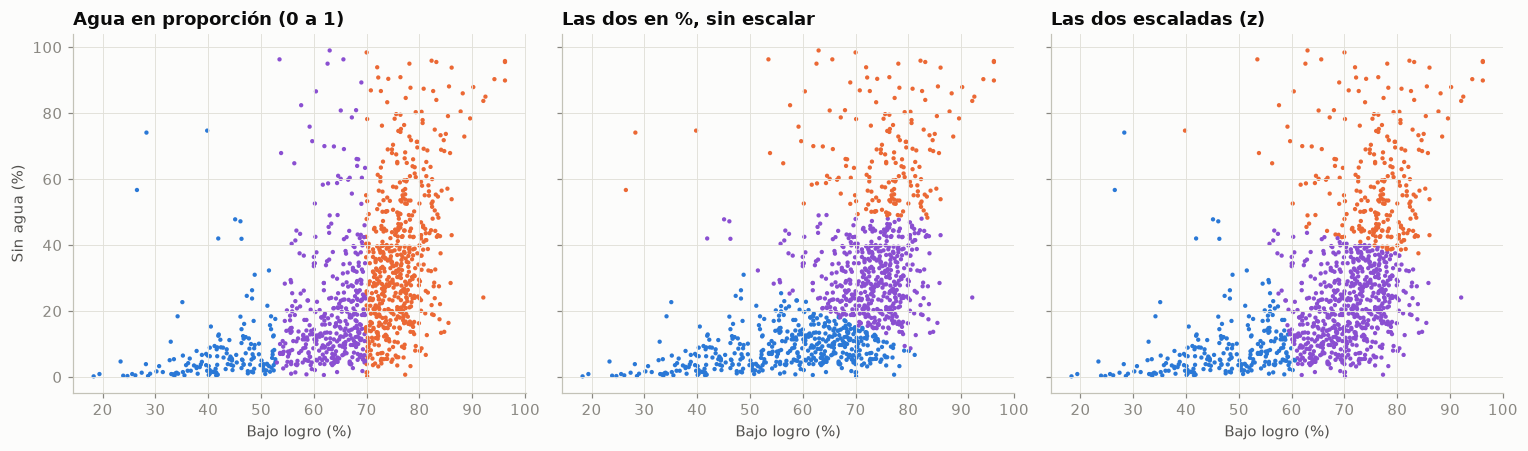

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (n, e) in zip(axs, etq.items()):
    ax.scatter(df[V[0]], df[V[1]], s=8, c=[COL_G[g] for g in e], edgecolor='none')
    ax.set(title=n, xlabel='Bajo logro (%)')
axs[0].set_ylabel('Sin agua (%)')
plt.tight_layout(); plt.show()

Con el agua en proporción, los grupos son franjas verticales: solo cortan el logro educativo. Escaladas, las dos variables participan en los cortes. **Desde aquí todo se hace con las variables escaladas (`Z`).**

## 3. El algoritmo, a mano

Cuatro pasos: elegir k, sembrar k centroides al azar, **asignar** cada municipio al centroide más cercano y **mover** cada centroide al promedio de su grupo; asignar y mover se repiten hasta que ningún municipio cambie de grupo. La **inercia** es la suma de las distancias al cuadrado de cada municipio a su centroide.

In [7]:
def kmeans_a_mano(X, k, semilla):
    """Algoritmo de Lloyd: sembrar k centroides al azar, asignar, mover y repetir hasta que nadie cambie."""
    r = np.random.default_rng(semilla)
    cen = X[r.choice(len(X), k, replace=False)]
    etq, historia = None, []
    while True:
        d = ((X[:, None, :] - cen[None, :, :]) ** 2).sum(axis=2)    # distancia² de cada punto a cada centroide
        nueva = d.argmin(axis=1)                                     # asignar
        if etq is not None and (nueva == etq).all():
            break
        etq = nueva
        cen = np.array([X[etq == j].mean(axis=0) for j in range(k)])  # mover
        historia.append(((X - cen[etq]) ** 2).sum())                  # inercia tras mover
    return etq, cen, historia

etq_m, cen_m, hist_m = kmeans_a_mano(Z, 3, semilla=7)
for i, h in enumerate(hist_m, 1):
    print(f'iteración {i}: inercia {h:,.1f}')
sk = kmeans(Z, 3)
print(f'scikit-learn (k-means++ y 10 inicios): inercia {sk.inertia_:,.1f} · ARI con la versión a mano: {adjusted_rand_score(etq_m, sk.labels_):.3f}')

iteración 1: inercia 931.1
iteración 2: inercia 709.0
iteración 3: inercia 694.2
iteración 4: inercia 690.2
iteración 5: inercia 688.9
iteración 6: inercia 688.6
iteración 7: inercia 688.4
iteración 8: inercia 688.3
scikit-learn (k-means++ y 10 inicios): inercia 688.3 · ARI con la versión a mano: 0.994


La inercia baja en cada iteración, de 931,1 a 688,3, y nunca sube: por eso el algoritmo siempre termina (aquí, en 8 iteraciones). La versión de scikit-learn llega a la misma inercia (688,3) y a casi los mismos grupos (ARI 0,994): solo difieren unos pocos municipios de la frontera.

## 4. Otro inicio, otro resultado

In [8]:
iner = pd.Series([KMeans(5, init='random', n_init=1, random_state=s).fit(Z).inertia_ for s in range(30)])
print('k = 5, 30 corridas con un solo inicio al azar:')
print(iner.round(1).value_counts().sort_index().to_string())
print(f'Con n_init=10 y k-means++: {kmeans(Z, 5).inertia_:,.1f}')

k = 5, 30 corridas con un solo inicio al azar:
407.900     5
408.000     4
408.100    16
409.600     2
444.400     1
445.700     1
447.100     1
Con n_init=10 y k-means++: 408.1


Con k = 5 y un solo inicio al azar, 25 de las 30 corridas terminan con una inercia cercana a 408 (entre 407,9 y 408,1), dos en 409,6 y tres quedan atrapadas entre 444,4 y 447,1: son **mínimos locales**, soluciones peores de las que el algoritmo ya no sale. Por eso scikit-learn repite con varios inicios (`n_init=10`) y se queda con la menor inercia, y siembra con **k-means++**, que pone los centroides iniciales lejos unos de otros: así llega a 408,1.

## 5. ¿Cuántos grupos? Codo y silueta

K-means no elige k. Dos ayudas: el **codo** de la inercia (más grupos siempre la bajan; se busca dónde deja de bajar mucho) y la **silueta** promedio. La silueta de un municipio es s = (b − a) / max(a, b), con a la distancia promedio a los de su grupo y b la distancia promedio al grupo vecino más cercano: cerca de 1, bien ubicado; cerca de 0, en la frontera; negativa, estaría mejor en el otro grupo.

In [9]:
ks = range(1, 9)
modelos = {k: kmeans(Z, k) for k in ks}
eleccion = pd.DataFrame({'inercia': [modelos[k].inertia_ for k in ks],
                         'silueta': [np.nan] + [silhouette_score(Z, modelos[k].labels_) for k in ks if k > 1]}, index=ks)
eleccion['baja de la inercia (%)'] = -100 * eleccion.inercia.pct_change()
eleccion.index.name = 'k'
eleccion

,inercia,silueta,baja de la inercia (%)
k,,,
1,"2,244.000",NaN,NaN
2,"1,197.909",0.411,46.617
3,688.344,0.443,42.538
4,503.078,0.398,26.915
5,408.071,0.371,18.885
6,354.672,0.383,13.086
7,306.511,0.355,13.579
8,267.512,0.365,12.724


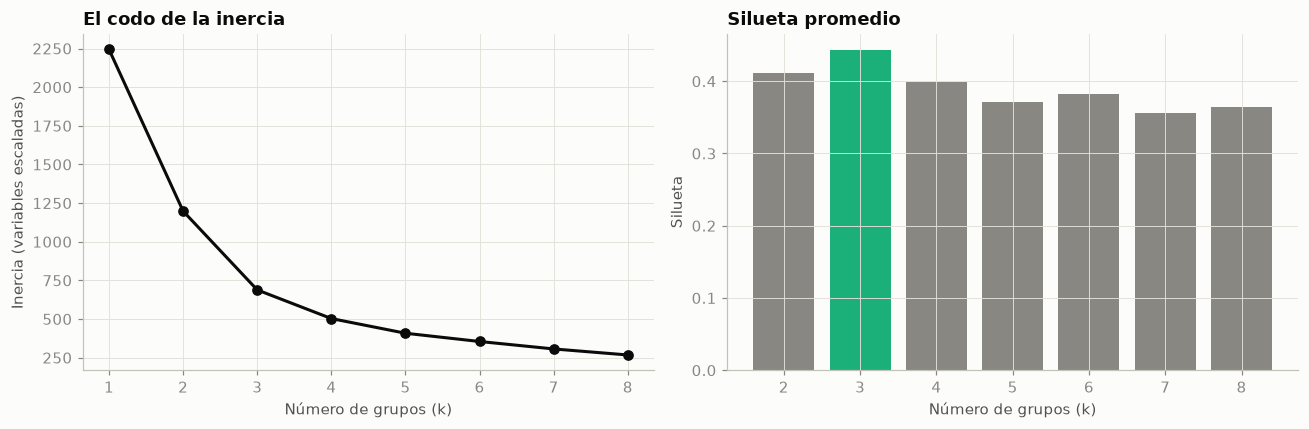

k con la silueta más alta: 3


In [10]:
K = int(eleccion.silueta.idxmax())
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(eleccion.index, eleccion.inercia, 'o-', color=TINTA)
axs[0].set(title='El codo de la inercia', xlabel='Número de grupos (k)', ylabel='Inercia (variables escaladas)')
axs[1].bar(eleccion.index[1:], eleccion.silueta[1:], color=[AQUA if k == K else GRIS for k in eleccion.index[1:]])
axs[1].set(title='Silueta promedio', xlabel='Número de grupos (k)', ylabel='Silueta')
plt.tight_layout(); plt.show()
print(f'k con la silueta más alta: {K}')

La inercia baja 46,6 % al pasar de 1 a 2 grupos, 42,5 % de 2 a 3 y solo 26,9 % de 3 a 4; después, menos de 19 %. El codo está entre k = 2 y k = 3. La silueta desempata: **k = 3** tiene la más alta (0,443), por encima de k = 2 (0,411) y k = 4 (0,398). Ninguna pasa de 0,5: hay grupos, pero con fronteras difusas, algo común en datos reales.

## 6. La silueta de cada municipio

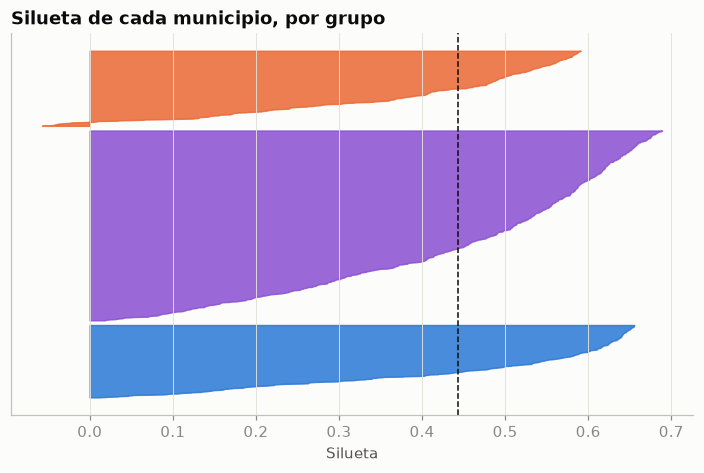

Silueta promedio: 0.443 · municipios con silueta negativa: 13 · entre 0 y 0,1: 51


,municipio,departamento,bajo_logro_educativo,sin_agua_mejorada,grupo,silueta
474,Chipaque,Cundinamarca,69.500,42.400,2,-0.057
769,San Pablo,Nariño,73.000,41.000,2,-0.050
985,Murillo,Tolima,78.100,38.700,2,-0.046
17,Belmira,Antioquia,69.900,42.500,2,-0.042
13,Arboletes,Antioquia,68.300,43.200,2,-0.042


In [11]:
df['grupo'] = ordenar(modelos[K].labels_, privacion)
df['silueta'] = silhouette_samples(Z, df.grupo)
fig, ax = plt.subplots(figsize=(8, 4.5))
y0 = 0
for g in range(K):
    s = np.sort(df.silueta[df.grupo == g].to_numpy())
    ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=COL_G[g], alpha=.85)
    y0 += len(s) + 15
ax.axvline(df.silueta.mean(), color=TINTA, ls='--', lw=1)
ax.set(title='Silueta de cada municipio, por grupo', xlabel='Silueta', yticks=[])
plt.show()
print(f'Silueta promedio: {df.silueta.mean():.3f} · municipios con silueta negativa: {(df.silueta < 0).sum()} · entre 0 y 0,1: {df.silueta.between(0, .1).sum()}')
df.nsmallest(5, 'silueta')[['municipio', 'departamento', *V, 'grupo', 'silueta']]

La silueta promedio es 0,443, pero no todos los municipios están igual de bien ubicados: 13 tienen silueta negativa y 51 están entre 0 y 0,1, en la frontera entre dos grupos. Los cinco peores (Chipaque, San Pablo, Murillo, Belmira y Arboletes) quedaron en el grupo de más privación, pero se parecen casi lo mismo al grupo vecino. **Un municipio de frontera no está «mal clasificado»**: no hay una respuesta correcta con la cual compararlo.

## 7. Perfil de los grupos

Los grupos se ordenaron de menos a más privación y se nombraron por su perfil. El IPM **no se usó para agrupar**: sirve para validar.

In [12]:
NOMBRES = ['Menos privaciones', 'Rezago educativo', 'Rezago y sin agua']
df['tipo'] = df.grupo.map(dict(enumerate(NOMBRES)))
perfil = df.groupby('tipo', sort=False).agg(municipios=('municipio', 'size'), bajo_logro=(V[0], 'mean'),
                                             sin_agua=(V[1], 'mean'), ipm=('ipm', 'mean')).loc[NOMBRES]
# el municipio más típico de cada grupo: el más cercano a su centroide (en z)
c_z = np.array([Z[df.grupo == g].mean(axis=0) for g in range(K)])
tipicos = [df[df.grupo == g].iloc[((Z[df.grupo == g] - c_z[g]) ** 2).sum(axis=1).argmin()] for g in range(K)]
perfil['más típico'] = [f'{t.municipio} ({t.departamento})' for t in tipicos]
perfil

,municipios,bajo_logro,sin_agua,ipm,más típico
tipo,,,,,
Menos privaciones,241,47.398,8.950,23.845,Florencia (Caquetá)
Rezago educativo,631,70.794,20.878,41.147,Palmas Del Socorro (Santander)
Rezago y sin agua,250,76.151,60.363,60.724,Cácota (Norte De Santander)


- **Menos privaciones** (241 municipios): 47,4 % con bajo logro y 9,0 % sin agua; IPM promedio 23,8 %.
- **Rezago educativo** (631): 70,8 % con bajo logro, pero solo 20,9 % sin agua; IPM 41,1 %.
- **Rezago y sin agua** (250): 76,2 % y 60,4 %; IPM 60,7 %.

El IPM sube de un grupo al otro (23,8 % → 41,1 % → 60,7 %) aunque K-means nunca lo vio: es una señal de que los grupos tienen sentido. El municipio más típico de cada grupo (el más cercano a su centroide) es Florencia (Caquetá), Palmas del Socorro (Santander) y Cácota (Norte de Santander).

*Nota.* La clase calcula K-means en el navegador y llega a 241, 644 y 237 municipios: es otra solución con prácticamente la misma inercia (688,3), que solo mueve municipios de la frontera entre los dos grupos de más privación.

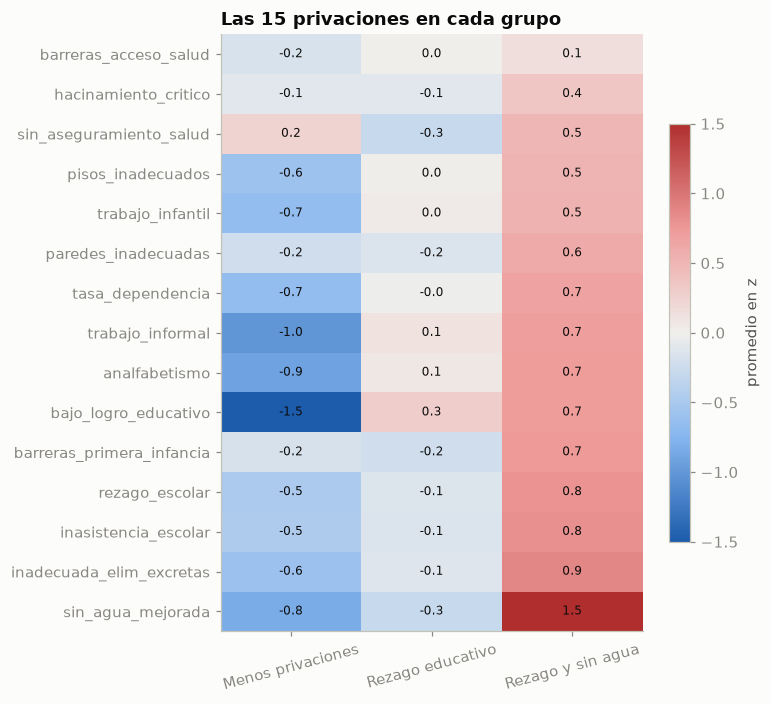

In [13]:
# las 15 privaciones, en z, promediadas por grupo: lo que distingue a cada tipo (aunque solo se agrupó con dos)
Z15 = pd.DataFrame(StandardScaler().fit_transform(df[PRIV]), columns=PRIV)
calor = Z15.groupby(df.tipo).mean().loc[NOMBRES].T.sort_values(NOMBRES[-1])
fig, ax = plt.subplots(figsize=(7, 6.5))
im = ax.imshow(calor, cmap=DIV, vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(K), NOMBRES, rotation=15); ax.set_yticks(range(len(PRIV)), calor.index); ax.grid(False)
for i in range(len(PRIV)):
    for j in range(K):
        ax.text(j, i, f'{calor.iat[i, j]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, shrink=.7, label='promedio en z'); ax.set_title('Las 15 privaciones en cada grupo')
plt.tight_layout(); plt.show()

Aunque se agrupó solo con dos privaciones, los grupos se distinguen en las demás. «Rezago y sin agua» está por encima del promedio en las 15 (sobre todo agua, 1,52 desviaciones; eliminación de excretas, 0,87; inasistencia escolar, 0,81). «Menos privaciones» está por debajo en 14 de las 15; la excepción es *sin aseguramiento en salud* (+0,24), más frecuente en los municipios más urbanos. «Rezago educativo» queda cerca del promedio en casi todo (entre −0,28 y 0,30).

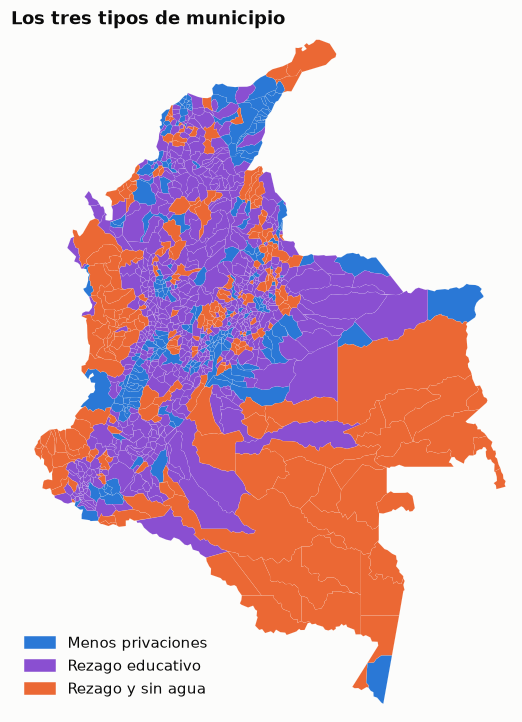

In [14]:
mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df[['cod_mpio', 'grupo']], on='cod_mpio', how='left')
fig, ax = plt.subplots(figsize=(7, 8))
for g in range(K):
    mapa[mapa.grupo == g].plot(ax=ax, color=COL_G[g], linewidth=0.05, edgecolor='white', label=NOMBRES[g])
if mapa.grupo.isna().any():
    mapa[mapa.grupo.isna()].plot(ax=ax, color='#e1e0d9')   # municipios sin dato
ax.set_title('Los tres tipos de municipio'); encuadre(ax)
ax.legend(handles=[mpl.patches.Patch(color=COL_G[g], label=NOMBRES[g]) for g in range(K)], loc='lower left')
plt.show()

Los tipos no están repartidos al azar: los municipios vecinos tienden a parecerse. «Rezago y sin agua» (naranja) cubre buena parte del sur y el oriente y de la costa Pacífica; «Menos privaciones» (azul) aparece en manchas pequeñas, sobre todo en la zona andina y el Caribe. Ojo: los municipios extensos de la Amazonía y la Orinoquía ocupan mucho mapa con poca población. La tabla siguiente lo resume por región, contando municipios.

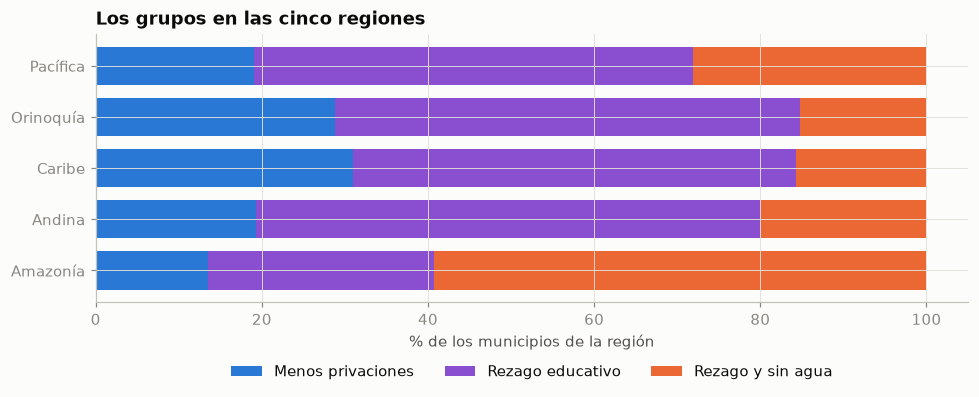

tipo,Menos privaciones,Rezago educativo,Rezago y sin agua
region,,,
Amazonía,13.600,27.100,59.300
Andina,19.200,60.900,19.900
Caribe,31.000,53.300,15.700
Orinoquía,28.800,55.900,15.300
Pacífica,19.100,52.800,28.100


In [15]:
region = pd.crosstab(df.region, df.tipo, normalize='index')[NOMBRES] * 100
ax = region.plot.barh(stacked=True, color=COL_G, figsize=(9, 3.8), width=.75)
ax.set(xlabel='% de los municipios de la región', ylabel='', title='Los grupos en las cinco regiones'); ax.legend(loc='upper center', bbox_to_anchor=(.5, -.18), ncol=3)
plt.tight_layout(); plt.show()
region.round(1)

En la Amazonía, el 59,3 % de los municipios es «Rezago y sin agua»; en la región Andina predomina «Rezago educativo» (60,9 %) y el Caribe tiene la mayor parte de «Menos privaciones» (31,0 %). Pero todas las regiones tienen al menos un 13,6 % de cada tipo: **los grupos no son las regiones**, las atraviesan.

## 8. Estabilidad

Diez veces: se toma el 80 % de los municipios al azar, se agrupa de nuevo y se compara con la agrupación de todos (ARI, en los mismos municipios). Se repite con k = 6 para comparar.

In [16]:
def estabilidad(k, veces=10, frac=.8):
    """ARI entre la agrupación de todos y la de submuestras del 80 %, comparadas en los mismos municipios."""
    todos = kmeans(Z, k).labels_
    r = np.random.default_rng(SEMILLA)
    out = []
    for i in range(veces):
        idx = r.choice(len(Z), int(frac * len(Z)), replace=False)
        out.append(adjusted_rand_score(todos[idx], kmeans(Z[idx], k, semilla=i).labels_))
    return out

estab = pd.DataFrame({f'k = {k}': estabilidad(k) for k in [K, K + 3]})
estab.agg(['mean', 'min', 'max']).T

,mean,min,max
k = 3,0.943,0.906,0.996
k = 6,0.863,0.453,0.974


Con k = 3 el ARI promedio es 0,943 y nunca baja de 0,906: los grupos casi no cambian con otra muestra. Con k = 6 el promedio baja a 0,863 y en una repetición cae a 0,453: esos grupos dependen de qué municipios entren. Es otro argumento a favor de k = 3.

## 9. Línea base: terciles del IPM

¿Hacía falta K-means? La alternativa sencilla es partir los municipios en tres niveles de IPM (bajo, medio y alto).

In [17]:
# Línea base: partir los municipios en tres niveles de IPM (terciles), sin K-means
df['tercil_ipm'] = pd.qcut(df.ipm, 3, labels=False)
base = pd.DataFrame({
    'K-means (k = 3)': [silhouette_score(Z, df.grupo), sum(((Z[df.grupo == g] - Z[df.grupo == g].mean(0)) ** 2).sum() for g in range(K))],
    'Terciles del IPM': [silhouette_score(Z, df.tercil_ipm), sum(((Z[df.tercil_ipm == g] - Z[df.tercil_ipm == g].mean(0)) ** 2).sum() for g in range(3))]},
    index=['silueta (z)', 'inercia (z)']).T
print(f'ARI entre los grupos de K-means y los terciles del IPM: {adjusted_rand_score(df.grupo, df.tercil_ipm):.3f}')
display(pd.crosstab(df.tipo, df.tercil_ipm.map({0: 'IPM bajo', 1: 'IPM medio', 2: 'IPM alto'})).loc[NOMBRES, ['IPM bajo', 'IPM medio', 'IPM alto']])
base

ARI entre los grupos de K-means y los terciles del IPM: 0.154


tercil_ipm,IPM bajo,IPM medio,IPM alto
tipo,,,
Menos privaciones,189,45,7
Rezago educativo,182,281,168
Rezago y sin agua,4,50,196


,silueta (z),inercia (z)
K-means (k = 3),0.443,688.339
Terciles del IPM,0.058,"1,433.721"


Las dos particiones se parecen poco (ARI 0,154). En el mismo plano escalado, K-means da grupos mucho más compactos (silueta 0,443 frente a 0,058; inercia 688 frente a 1.434). Lo más útil está en la tabla: el grupo «Rezago educativo» tiene municipios de IPM bajo (182), medio (281) y alto (168). **Dos municipios con el mismo IPM pueden ser pobres por razones distintas**, y eso es lo que los grupos dejan ver.

## 10. Con las 15 privaciones

In [18]:
g15 = ordenar(kmeans(Z15, K).labels_, df.ipm.to_numpy())
print(f'Silueta con las 15 privaciones: {silhouette_score(Z15, g15):.3f}')
print(f'ARI frente a los grupos con 2 variables: {adjusted_rand_score(df.grupo, g15):.3f}')
pd.crosstab(df.tipo, pd.Series(g15, name='grupo con 15 privaciones (0 = menos IPM)')).loc[NOMBRES]

Silueta con las 15 privaciones: 0.215
ARI frente a los grupos con 2 variables: 0.126


grupo con 15 privaciones (0 = menos IPM),0,1,2
tipo,,,
Menos privaciones,204,37,0
Rezago educativo,324,304,3
Rezago y sin agua,23,168,59


Con las 15 privaciones escaladas, la silueta baja a 0,215 y los grupos cambian mucho (ARI 0,126 frente a los de dos variables): por ejemplo, de los 631 municipios de «Rezago educativo», 324 quedan en el grupo de menos IPM y 304 en el del medio. **Los grupos dependen de las variables que se elijan**, y esa es una decisión de quien investiga. Con 15 variables, además, ya no se pueden dibujar: el ejercicio 02 las resume primero con componentes principales (PCA) y luego agrupa.

## Conclusiones

1. **Escalar no es opcional.** Sin escalar, entre el 28,7 % y el 43,3 % de los municipios cambia de grupo, según las unidades.
2. **El algoritmo baja la inercia en cada paso** (de 931,1 a 688,3), pero puede quedar en un mínimo local: con k = 5, 3 de 30 inicios al azar terminaron en 444–447 en vez de 408. Use varios inicios y k-means++.
3. **k lo decide quien investiga.** El codo sugiere entre 2 y 3; la silueta (0,443) y la estabilidad (ARI 0,943) apoyan k = 3.
4. **Los grupos tienen sentido:** el IPM, que no se usó, sube de 23,8 % a 41,1 % y a 60,7 %, y los grupos se distinguen también en las otras 13 privaciones.
5. **No son las regiones ni los niveles de IPM:** todas las regiones tienen de los tres tipos, y el ARI con los terciles del IPM es solo 0,154.
6. **Límites:** las fronteras son difusas (13 municipios con silueta negativa), y con otras variables los grupos cambian (ARI 0,126 con las 15 privaciones).

## Retos

1. **Otra pareja de variables.** Agrupe con *analfabetismo* y *trabajo informal*. ¿Qué k sugieren el codo y la silueta? ¿Qué nombre le pondría a cada grupo?
2. **Escalar de otra forma.** Cambie `StandardScaler` por `MinMaxScaler` (lleva cada variable a 0–1). ¿Cuántos municipios cambian de grupo frente a la versión con z?
3. **Un municipio en la frontera.** Elija uno de los 13 con silueta negativa, busque sus dos centroides más cercanos y explique en palabras por qué está entre dos grupos.
4. **Clustering jerárquico.** Agrupe las mismas dos variables escaladas con `AgglomerativeClustering(n_clusters=3, linkage='ward')` y compárelo con K-means con el ARI. ¿Coinciden?
5. **Sin los atípicos.** Quite los municipios con silueta negativa, vuelva a agrupar y compare la silueta promedio. ¿Mejora? ¿Es correcto hacerlo en una investigación?